# Лабораторная работа 4. Кластеризация

|  |  |
|---|---|
| Дисциплина | Машинное обучение |
| Студент | Масенькин Максим |
| Группа | ПИбд-41 |
| Вариант | 20 |

## Задание

Использовать метод кластеризации по варианту для своих данных, самостоятельно сформулировав
задачу. Интерпретировать результаты и оценить, насколько хорошо он подходит для решения
сформулированной задачи.

| Пункт задания | Вариант 20 |
|---|---|
| Метод | K-means (20 % 5 = 0) |
| Данные | сделки инсайдеров Tesla, 156 записей |
| Задача | выделить типовые сделки по сумме, числу акций и типу транзакции |
| Признаки | логарифм суммы сделки, логарифм числа акций, тип транзакции |
| Пособие | «Теория и практика машинного обучения»: оценка качества кластеризации и силуэт — стр. 25–28, стандартизация — стр. 185–187, листинги 20–21 |

## Ход работы

1. Загрузить данные о сделках и подготовить признаки.
2. Подобрать число кластеров методом локтя и силуэта.
3. Обучить модель и показать кластеры на графике.
4. Объяснить кластеры.
5. Оценить выбранный метод кластеризации.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples, silhouette_score
from sklearn.preprocessing import StandardScaler

from mllab import RANDOM_STATE
from mllab.datasets import load_tesla
from mllab.plotting import draw_clusters, draw_silhouette


K_RANGE = range(2, 11)
CLUSTERS = 5
N_INIT = 10
SINGLE_RUNS = 50
COLORS = {1: "#6250d6", 2: "#eda100", 3: "#2a78d6", 4: "#eb6834", 5: "#1baf7a"}

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10})
pd.set_option("display.width", 120)

## 1. Данные и признаки

Набор содержит 156 сделок семи инсайдеров Tesla с ноября 2021 по декабрь 2022. Сделки сильно
различаются по масштабу: одни продают несколько тысяч акций, другие — миллионы. 

Задача работы —
разбить сделки на группы похожих по сумме, числу акций и типу и проверить, совпадают ли эти группы
с должностями инсайдеров. Заранее можно ожидать три группы: крупные продажи генерального
директора, исполнение опционов менеджментом и сделки членов совета директоров.

Ниже число сделок каждого типа по должностям: генеральный директор Илон Маск (CEO), финансовый
директор (CFO), главный бухгалтер (CAO), вице-президент по силовым установкам и энергетике (SVP) и
три члена совета директоров (Director).

In [2]:
tesla = load_tesla()
pd.crosstab(tesla["relationship"], tesla["transaction"], margins=True, margins_name="total")

transaction,Option Exercise,Sale,total
relationship,,,
CEO,10,43,53
Chief Accounting Officer,9,10,19
Chief Financial Officer,8,16,24
Director,8,8,16
SVP Powertrain and Energy Eng.,22,22,44
total,57,99,156


На Маска приходится 53 сделки из 156, т. е. треть набора, и 43 из них — продажи. У остальных
продаж и исполнений опционов примерно поровну. Исполнение опциона — это покупка акций компании
по заранее оговорённой цене.

Признаки для кластеризации:

- `log_value` — логарифм суммы сделки $\ln(1 + \text{сумма})$;
- `log_shares` — логарифм числа акций $\ln(1 + \text{акций})$;
- `sale` — тип транзакции: 1 для продажи, 0 для исполнения опциона.

Суммы лежат от нуля до 2.28 млрд \$, число акций — от 121 до 11.92 млн. K-means группирует точки
по расстоянию между ними, и в долларах расстояние от одной продажи Маска до остальных сделок было
бы намного больше всех прочих расстояний. После приведения к логарифмической шкале важна разница
в разах: продажи на 1 млн и 10 млн \$ отстоят друг от друга так же, как продажи на 10 млн и
100 млн \$. Единица добавлена из-за 18 сделок с нулевой суммой.

In [3]:
features = pd.DataFrame(
    {
        "log_value": np.log1p(tesla["value"]),
        "log_shares": np.log1p(tesla["shares"]),
        "sale": (tesla["transaction"] == "Sale").astype(int),
    }
)
features.agg(["mean", "std", "min", "max"]).T.round(2)

,mean,std,min,max
log_value,14.08,5.83,0.0,21.55
log_shares,10.18,2.63,4.8,16.29
sale,0.63,0.48,0.0,1.00


Разброс признаков после приведения к логарифмической шкале всё ещё разный: стандартное отклонение
`log_value` 5.83, `log_shares` 2.63, `sale` 0.48. Расстояние между двумя сделками складывается из
разностей по всем признакам, поэтому признак с большим разбросом его и определяет. Продажа и
исполнение опциона отличаются по `sale` на 1, а суммы двух сделок одного типа часто отличаются по
`log_value` на 5 и больше, так что тип сделки почти не повлиял бы на результат.

Поэтому признаки стандартизируются: из каждого вычитается среднее, и результат делится на
стандартное отклонение,

$$z = \frac{x - \bar{x}}{\sigma} .$$

После этого у всех признаков среднее 0 и отклонение 1. Разница между продажей и опционом
становится равной $1 / 0.48 \approx 2.07$, т. е. двум стандартным отклонениям суммы.

In [4]:
scaler = StandardScaler()
Z = scaler.fit_transform(features)
pd.DataFrame(Z, columns=features.columns).agg(["mean", "std", "min", "max"]).T.round(2).replace(
    -0.0, 0.0
)

,mean,std,min,max
log_value,0.0,1.0,-2.42,1.29
log_shares,0.0,1.0,-2.05,2.33
sale,0.0,1.0,-1.32,0.76


## 2. Алгоритм K-means и выбор числа кластеров

K-means делит $n$ точек на $k$ кластеров. У каждого кластера есть центр $\mu_j$, и точка
относится к кластеру с ближайшим центром. Алгоритм минимизирует сумму квадратов расстояний от
точек до центров их кластеров, которую называют инерцией:

$$J = \sum_{i=1}^{n} \lVert z_i - \mu_{c(i)} \rVert^2 ,$$

где $c(i)$ — номер кластера точки $z_i$. Чем меньше $J$, тем плотнее точки собраны вокруг своих
центров.

Алгоритм начинает с $k$ начальных центров и повторяет два шага:

1. Каждая точка относится к ближайшему центру.
2. Каждый центр переносится в среднее точек своего кластера.

Ни один из шагов не увеличивает $J$, поэтому через несколько повторений точки перестают
переходить между кластерами, и алгоритм останавливается. Пусть на прямой есть точки 1, 2, 9, 10,
$k = 2$, и начальные центры 1 и 2:

- точка 1 ближе к центру 1, точки 2, 9, 10 — к центру 2; центры переезжают в 1 и 7;
- теперь точка 2 ближе к центру 1 ($\lvert 2 - 1 \rvert = 1$ против $\lvert 2 - 7 \rvert = 5$);
  центры переезжают в 1.5 и 9.5;
- точки больше не меняют кластер, $J = 4 \cdot 0.5^2 = 1$.

Результат зависит от начальных центров. В scikit-learn они выбираются способом k-means++: первым
центром берётся случайная точка, следующие тоже выбираются случайно, но далёкие от уже выбранных
центров точки получают большую вероятность. Так начальные центры редко оказываются в одной
группе. Кроме того, алгоритм запускается `n_init = 10` раз с разными начальными центрами, и из
запусков берётся тот, у которого $J$ меньше.

Число кластеров $k$ задаётся заранее. Его подбирают двумя способами.

### Метод локтя

С ростом $k$ инерция всегда уменьшается: если каждая точка станет отдельным кластером, $J = 0$.
Поэтому ищут $k$, после которого инерция падает уже медленно. На графике в этом месте излом,
похожий на локоть.

### Метод силуэта

Силуэт оценивает, насколько точка ближе к своему кластеру, чем к соседнему:

$$s_i = \frac{b_i - a_i}{\max(a_i, b_i)} ,$$

где $a_i$ — среднее расстояние от точки $i$ до остальных точек её кластера, $b_i$ — среднее
расстояние до точек ближайшего чужого кластера. Силуэт лежит от −1 до 1:

- если $a_i = 1$, $b_i = 4$, то $s_i = 3 / 4 = 0.75$ — точка хорошо отделена от соседнего
  кластера;
- если $a_i = b_i = 3$, то $s_i = 0$ — точка на границе двух кластеров;
- отрицательный $s_i$ значит, что точка ближе к чужому кластеру, чем к своему.

Для каждого $k$ силуэт усредняют по всем точкам и выбирают $k$ с наибольшим средним: при нём
точки лучше всего отделены от соседних кластеров. Ниже K-means обучен для $k$ от 2 до 10.

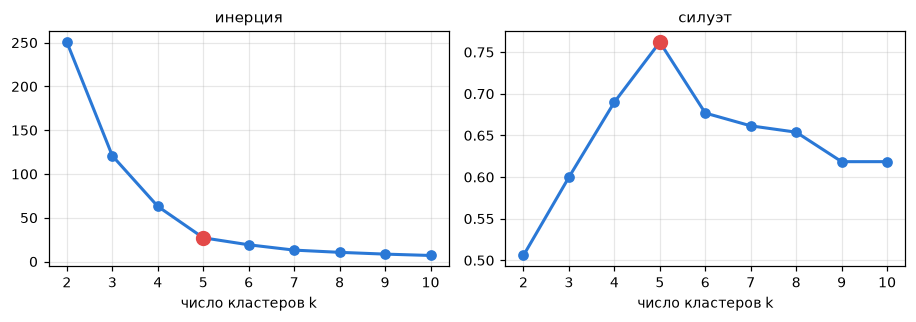

k,2,3,4,5,6,7,8,9,10
inertia,250.633,120.825,63.09,27.219,19.207,13.140,10.592,8.563,7.011
silhouette,0.506,0.600,0.69,0.762,0.677,0.662,0.654,0.618,0.619


In [5]:
scan = []
for k in K_RANGE:
    model = KMeans(k, n_init=N_INIT, random_state=RANDOM_STATE).fit(Z)
    scan.append(
        {"k": k, "inertia": model.inertia_, "silhouette": silhouette_score(Z, model.labels_)}
    )
scan = pd.DataFrame(scan).set_index("k")

fig, (ax_elbow, ax_silhouette) = plt.subplots(1, 2, figsize=(8.4, 3.0))
for ax, column, title in (
    (ax_elbow, "inertia", "инерция"),
    (ax_silhouette, "silhouette", "силуэт"),
):
    ax.plot(scan.index, scan[column], marker="o", color="#2a78d6", linewidth=2)
    ax.plot(CLUSTERS, scan.loc[CLUSTERS, column], marker="o", markersize=9, color="#e34948")
    ax.set_xlabel("число кластеров k")
    ax.set_title(title)
    ax.set_xticks(list(K_RANGE))
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

scan.T.round(3)

Инерция падает со 120.8 при $k = 3$ до 63.1 при $k = 4$ и до 27.2 при $k = 5$, а дальше
уменьшается на единицы: при $k = 6$ она 19.2. Локоть приходится на $k = 5$. Силуэт при этом
же $k$ наибольший, 0.762, и при 6 кластерах снижается до 0.677. Оба способа дают $k = 5$.

Чтобы проверить, насколько решение зависит от начальных центров, K-means с $k = 5$ запущен 50 раз
с одним набором начальных центров (`n_init = 1`).

In [6]:
single = pd.Series(
    [KMeans(CLUSTERS, n_init=1, random_state=seed).fit(Z).inertia_ for seed in range(SINGLE_RUNS)]
)
single.round(1).value_counts().sort_index().rename_axis("inertia").rename("runs").to_frame().T

inertia,27.2,55.1,56.2,56.3,56.9,74.2,74.6
runs,42,2,2,1,1,1,1


В 42 запусках из 50 алгоритм пришёл к одному и тому же решению с $J = 27.2$. В остальных восьми
он остановился с инерцией от 55 до 75, т. е. в два-три раза хуже. Это локальные минимумы: точки
уже не переходят между кластерами, но разбиение не лучшее. Если запустить алгоритм 10 раз, шанс,
что все запуски окажутся неудачными, около $(8/50)^{10}$, поэтому `n_init = 10` хватает.

## 3. Кластеры

Номера кластеров scikit-learn назначает произвольно, поэтому они перенумерованы: сначала продажи,
затем исполнения опционов, внутри — по возрастанию суммы. Центр кластера найден в логарифмической
шкале, и в таблице он переведён обратно в доллары и акции. Такой центр показывает типичную сделку
кластера.

In [7]:
kmeans = KMeans(CLUSTERS, n_init=N_INIT, random_state=RANDOM_STATE).fit(Z)

centers = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=features.columns)
order = centers.sort_values(["sale", "log_value"], ascending=[False, True]).index
renumber = {old: new for new, old in enumerate(order, start=1)}
cluster = pd.Series(kmeans.labels_, index=tesla.index).map(renumber).rename("cluster")
centers = centers.rename(index=renumber).sort_index().rename_axis("cluster")

pd.DataFrame(
    {
        "deals": cluster.value_counts().sort_index(),
        "center_sale": centers["sale"].round(2).abs(),
        "center_value": np.expm1(centers["log_value"]).round(-3).astype(int),
        "center_shares": np.expm1(centers["log_shares"]).round(-2).astype(int),
    }
)

,deals,center_sale,center_value,center_shares
cluster,,,,
1,57,1.0,1900000,3800
2,42,1.0,474962000,607200
3,29,0.0,338000,8200
4,18,0.0,0,4500
5,10,0.0,12868000,2062200


Доля продаж в каждом центре равна 0 или 1 — это означает, что все пять кластеров однородны по типу сделки. Признак
`sale` принимает два значения, поэтому кластеры показаны на двух графиках — для продаж и для
исполнений опционов. Крестом отмечен центр кластера. Оси логарифмические, как и признаки.

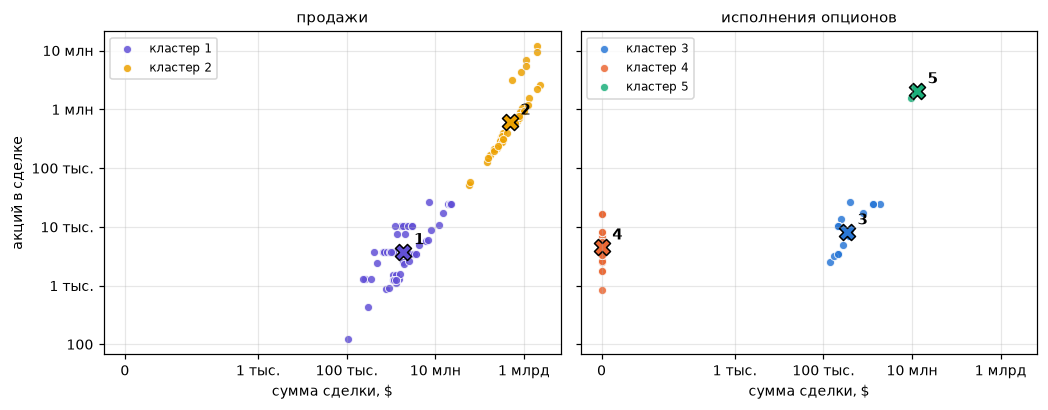

In [8]:
DOLLAR_TICKS = {0: "0", 1e3: "1 тыс.", 1e5: "100 тыс.", 1e7: "10 млн", 1e9: "1 млрд"}
SHARE_TICKS = {
    1e2: "100",
    1e3: "1 тыс.",
    1e4: "10 тыс.",
    1e5: "100 тыс.",
    1e6: "1 млн",
    1e7: "10 млн",
}

points = features[["log_value", "log_shares"]].to_numpy()
labels = cluster.to_numpy()
panels = {"продажи": [1, 2], "исполнения опционов": [3, 4, 5]}

fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.8), sharex=True, sharey=True)
for ax, (title, members) in zip(axes, panels.items(), strict=True):
    draw_clusters(
        ax,
        points,
        labels,
        {label: centers.loc[label, ["log_value", "log_shares"]].to_numpy() for label in members},
        {label: COLORS[label] for label in members},
    )
    ax.set_title(title)
    ax.set_xticks(np.log1p(list(DOLLAR_TICKS)), list(DOLLAR_TICKS.values()))
    ax.set_yticks(np.log1p(list(SHARE_TICKS)), list(SHARE_TICKS.values()))
    ax.set_xlabel("сумма сделки, $")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="upper left")
axes[0].set_ylabel("акций в сделке")
fig.tight_layout()
plt.show()

Среди продаж кластер 1 — сделки на тысячи и десятки тысяч акций, кластер 2 — на сотни тысяч и
миллионы. Среди опционов кластер 4 стоит у нуля: это сделки с нулевой суммой. Кластер 5 — десять
почти одинаковых сделок примерно на 2 млн акций, на графике они слились в одну точку.

Точки внутри кластеров вытянуты вдоль диагонали: чем больше акций, тем больше сумма.

## 4. Интерпретация кластеров

Ниже состав кластеров по должностям. Отдельно указано, сколько сделок в кластере у Маска и
сколько с нулевой суммой.

In [9]:
ROLES = {
    "Chief Accounting Officer": "CAO",
    "Chief Financial Officer": "CFO",
    "SVP Powertrain and Energy Eng.": "SVP",
}

composition = pd.crosstab(cluster, tesla["relationship"].replace(ROLES)).rename_axis(columns=None)
composition["musk"] = (tesla["insider"] == "Musk Elon").groupby(cluster).sum()
composition["zero_value"] = (tesla["value"] == 0).groupby(cluster).sum()
composition

,CAO,CEO,CFO,Director,SVP,musk,zero_value
cluster,,,,,,,
1,10,1,16,8,22,1,0
2,0,42,0,0,0,42,0
3,3,0,2,8,16,0,0
4,6,0,6,0,6,0,18
5,0,10,0,0,0,10,0


Каждый кластер получил понятный смысл:

| Кластер | Сделки | Сделок | Типичная сделка |
|---|---|---|---|
| 1 | продажи менеджмента и совета директоров | 57 | 3.8 тыс. акций на 1.9 млн \$ |
| 2 | продажи Маска | 42 | 607 тыс. акций на 475 млн \$ |
| 3 | исполнение опционов менеджментом и советом директоров | 29 | 8.2 тыс. акций на 338 тыс. \$ |
| 4 | сделки с нулевой суммой | 18 | 4.5 тыс. акций на 0 \$ |
| 5 | исполнение опционов Маском | 10 | 2.1 млн акций на 12.9 млн \$ |

Уточнения по кластерам:

- В кластер 1 попала одна продажа Маска, самая маленькая у него — 10 655 акций на 11.9 млн \$.
- В кластере 2 самая крупная продажа — на 2.28 млрд \$.
- В кластере 3 цена исполнения от 15 до 74 \$ при рыночной цене в сотни долларов.
- В кластере 4 по шесть сделок у главного бухгалтера, финансового директора и вице-президента.
  Скорее всего, это ежеквартальное начисление акций в счёт вознаграждения.
- В кластере 5 сделки ноября и декабря 2021 года, в каждой 1.6–2.2 млн акций по цене 6.24 \$.

Ожидание подтвердилось частично:

- Сделки Маска выделились в два своих кластера, 2 и 5, — туда попали 52 из 53 его сделок.
- Исполнения опционов остальным руководством разделились на платные (кластер 3) и бесплатные
  (кластер 4).
- Отдельного кластера директоров не получилось. Их продажи в среднем крупнее менеджерских
  (19 тыс. акций против 4.2 тыс.), но промежутка между ними нет, поэтому директора оказались у
  верхнего края кластеров 1 и 3.

Кластеры совпадают с должностями только там, где у должности свой масштаб сделок, отделённый от
остальных промежутком. Так получилось только у Маска.

## 5. Применимость K-means

Силуэт считается для каждой сделки отдельно, и по нему видно, какие сделки лежат на границе
кластеров. На диаграмме ниже силуэты отсортированы внутри каждого кластера, высота полосы равна
числу сделок в кластере. Пунктиром отмечен средний силуэт.

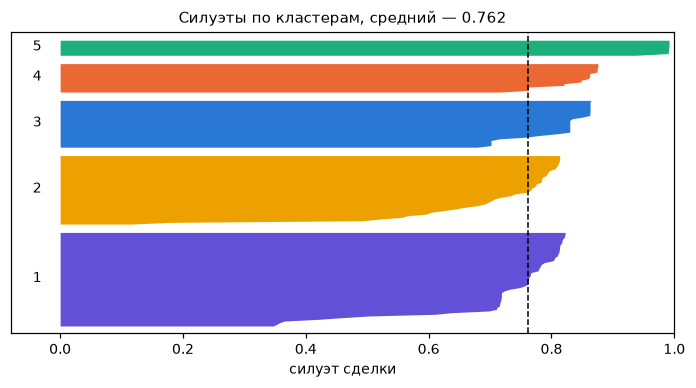

cluster,1,2,3,4,5
mean,0.720,0.701,0.810,0.835,0.986
min,0.347,0.116,0.679,0.717,0.937


In [10]:
silhouette = silhouette_samples(Z, kmeans.labels_)

fig, ax = plt.subplots(figsize=(6.4, 3.6))
draw_silhouette(ax, silhouette, labels, COLORS)
ax.set_xlabel("силуэт сделки")
ax.set_title(f"Силуэты по кластерам, средний — {silhouette.mean():.3f}")
fig.tight_layout()
plt.show()

pd.Series(silhouette).groupby(labels).agg(["mean", "min"]).rename_axis("cluster").round(3).T

Отрицательных силуэтов нет, т. е. ни одна сделка не оказалась ближе к чужому кластеру, чем к
своему. У кластера 5 силуэт почти 1: десять одинаковых сделок далеко от остальных. Слабее всего
кластеры 1 и 2, у которых в хвосте силуэты 0.1–0.4. Ниже шесть сделок с наименьшим силуэтом.

In [11]:
weakest = pd.Series(silhouette, index=tesla.index).nsmallest(6)
tesla.loc[weakest.index, ["insider", "date", "transaction", "shares", "value"]].assign(
    cluster=cluster[weakest.index], silhouette=weakest.round(3)
)

,insider,date,transaction,shares,value,cluster,silhouette
151,Musk Elon,2021-11-11,Sale,52099,57217365,2,0.116
153,Musk Elon,2021-11-10,Sale,58101,59206941,2,0.177
100,DENHOLM ROBYN M,2022-02-01,Sale,25000,23089129,1,0.347
95,DENHOLM ROBYN M,2022-03-01,Sale,25000,21694957,1,0.353
70,DENHOLM ROBYN M,2022-05-02,Sale,24779,21541489,1,0.357
64,DENHOLM ROBYN M,2022-06-01,Sale,25000,18933242,1,0.366


Это первые две продажи Маска 10 и 11 ноября 2021 года, на 52–58 тыс. акций, и продажи Робин
Денхолм из совета директоров на 25 тыс. акций и около 20 млн \$. По масштабу они лежат между
кластерами 1 и 2: самые мелкие продажи Маска и самые крупные продажи директоров.

### Форма кластеров

K-means относит точку к ближайшему центру, поэтому лучше всего находит круглые облака. Сумма
сделки равна цене акции, умноженной на число акций, а в логарифмической шкале — сумме:
$\ln(\text{сумма}) \approx \ln(\text{цена}) + \ln(\text{акций})$. Внутри кластера цена меняется
меньше, чем число акций, поэтому облака вытягиваются вдоль диагонали. Ниже разброс и корреляция
признаков внутри кластеров.

In [12]:
spread = features.groupby(cluster)[["log_value", "log_shares"]].std()
spread["corr"] = [
    group["log_value"].corr(group["log_shares"]) if group["log_value"].std() > 0 else np.nan
    for _, group in features.groupby(cluster)
]
spread.round(2).rename(columns={"log_value": "std_log_value", "log_shares": "std_log_shares"})

,std_log_value,std_log_shares,corr
cluster,,,
1,1.17,1.09,0.78
2,0.88,1.28,0.90
3,0.74,0.78,0.78
4,0.00,0.84,NaN
5,0.10,0.10,1.00


В кластерах 1–3 корреляция 0.78–0.90, т. е. облака вытянуты (у кластера 4 сумма всегда нулевая,
корреляция не определена). Кластеры 1 и 2 лежат на одной диагонали, и граница между ними проходит
поперёк неё — как раз у этой границы оказались сделки с наименьшим силуэтом. Промежуток по сумме
между кластерами большой, поэтому вытянутость решение не испортила.

### Перекос в сторону одного инсайдера

На Маска приходится треть сделок, и все 42 сделки дороже 50 млн \$ совершил он. Два кластера из
пяти состоят только из его сделок, а все остальные инсайдеры делят три кластера. K-means ничего не
знает об инсайдерах и группирует сделки по масштабу, но масштаб Маска настолько отличается от
остальных, что его сделки выделяются сами.

### Оценка метода

Для этого набора K-means подходит: группы сделок хорошо разделены, средний силуэт 0.762, и каждый
кластер можно объяснить. При этом K-means лучше работает с круглыми кластерами одного размера, а
здесь они вытянуты и содержат от 10 до 57 сделок.

## Выводы

1. Сформулирована задача кластеризации сделок инсайдеров Tesla по сумме, числу акций и типу
   транзакции. Сумма и число акций приведены к логарифмической шкале, все три признака
   стандартизированы.
2. Метод локтя и средний силуэт указали на одно и то же число кластеров, $k = 5$. Средний силуэт
   при нём 0.762.
3. Выделены пять кластеров: продажи менеджмента и директоров, продажи Маска, платное исполнение
   опционов менеджментом и директорами, сделки с нулевой суммой и исполнение опционов Маском.
4. Отдельно выделились сделки Маска, 52 из 53. Члены совета директоров отдельного кластера не
   образовали: их сделки крупнее менеджерских, но без промежутка между ними.
5. K-means подходит для этих данных, т. к. группы разделены большими промежутками. Кластеры при
   этом вытянуты вдоль диагонали «акции — сумма» и различаются по размеру, а слабее всего
   разделены продажи Маска и Денхолм на 20–60 млн \$.

## Контрольные вопросы

**1. Какую задачу для решения вы сформулировали?**

Задача кластеризации: разбить сделки инсайдеров Tesla на группы похожих по сумме, числу акций и
типу транзакции и проверить, соответствуют ли группы должностям инсайдеров. Это обучение без
учителя: правильного разбиения нет, и смысл кластерам даётся после обучения по составу.

**2. Как вы оценили качество кластеризации?**

По инерции — показывает, насколько плотно точки собраны вокруг центров. Она всегда уменьшается с увеличением количества кластеров, поэтому по ней ищется излом (метод локтя).

По силуэту — сравнивает расстояние точки до своего кластера с расстоянием до ближайшего чужого. По
среднему силуэту ищется максимум, при $k = 5$ он равен 0.762. Силуэты отдельных сделок показали,
какие из них лежат на границе кластеров.

Кроме того, кластеры проверены на осмысленность по составу должностей.

**3. Расскажите подробнее об используемом вами алгоритме кластеризации.**

K-means минимизирует инерцию, чередуя два шага: отнести каждую точку к ближайшему центру и
перенести центр в среднее точек кластера. Число кластеров задаётся заранее. Алгоритм сходится к
локальному минимуму, который зависит от начальных центров, поэтому центры выбираются способом
k-means++, а сам алгоритм запускается несколько раз. Расстояние евклидово, поэтому признаки
нужно приводить к одной шкале. Метод предполагает кластеры округлой формы и сравнимого размера и
чувствителен к выбросам, т. к. центр — это среднее.